# Variabilidade, intervalos e testes de hipótese

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/02_incerteza_e_testes_de_hipotese.ipynb)

O Notebook 01 estimou uma diferença observada. Agora perguntamos que variação
esperaríamos se o procedimento de obtenção dos dados pudesse ser repetido.

## 1. Antes da inferência: de onde vêm os dados?

Variabilidade amostral é a variação de uma estatística entre amostras obtidas
pelo mesmo procedimento. Ela não é sinônimo de erro de medição, transformação,
lacuna de cobertura ou mudança histórica.

| Situação | O intervalo amostral resolve? | Razão |
|---|---|---|
| amostra probabilística de uma população definida | pode quantificar parte da incerteza | o desenho sustenta a generalização |
| corpus completo para a pergunta | geralmente não é a questão central | a diferença do corpus já é observada |
| coleção de conveniência | não corrige a seleção | a reamostragem herda a composição disponível |

Os 24 registros fictícios serão tratados como se viessem de um procedimento
repetível apenas para compreender o método. Não faremos inferências históricas.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_05'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


Definido o alvo hipotético, podemos observar como uma estimativa varia entre
reamostras.

## 2. *Bootstrap* e distribuição da estimativa

![Uma amostra observada produz três reamostras com reposição, que convergem para uma distribuição bootstrap; a figura alerta que estrutura e vieses são herdados.](imagens/02_fluxo_bootstrap.svg)

Para cada repetição, sorteamos com reposição dentro de cada grupo e recalculamos
$\Delta_b=\bar{x}_{A,b}-\bar{x}_{B,b}$. A coleção dos valores aproxima a
variabilidade da estimativa sob o procedimento adotado.

In [2]:
import numpy as np
import pandas as pd
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd())) if str(Path.cwd()) not in sys.path else None
from graficos import histograma_referencia
from IPython.display import display

dados = pd.read_csv("dados/documentos.csv")
a = dados.loc[dados["local"].eq("Capital"), "palavras"].to_numpy()
b = dados.loc[dados["local"].eq("Interior"), "palavras"].to_numpy()
diferenca_observada = a.mean() - b.mean()
rng = np.random.default_rng(20260906)
B = 4000
diferencas_bootstrap = np.array([
    rng.choice(a, size=len(a), replace=True).mean()
    - rng.choice(b, size=len(b), replace=True).mean()
    for _ in range(B)
])
pd.Series(diferencas_bootstrap).describe(percentiles=[0.025, 0.5, 0.975])

count    4000.000000
mean     -198.928146
std       142.248368
min      -715.583333
2.5%     -505.125000
50%      -185.541667
97.5%      49.000000
max       213.500000
dtype: float64

A distribuição não mostra 4.000 novos passados possíveis: mostra a variação
produzida pela regra de reamostragem sobre os dados observados.

## 3. Intervalo de confiança

Usaremos o intervalo percentil introdutório:

$$
IC_{95\%}=\left[Q_{0{,}025}(\Delta_b),Q_{0{,}975}(\Delta_b)\right].
$$

Em repetições do procedimento, cerca de 95% dos intervalos construídos desta
maneira cobririam o parâmetro-alvo sob as condições do método. Depois de
calculado, não dizemos que há 95% de probabilidade frequentista de o parâmetro
fixo estar neste intervalo. O intervalo tampouco contém 95% dos documentos.

,estimativa,limite inferior,limite superior,unidade
0,-203.17,-505.12,49.0,palavras por documento


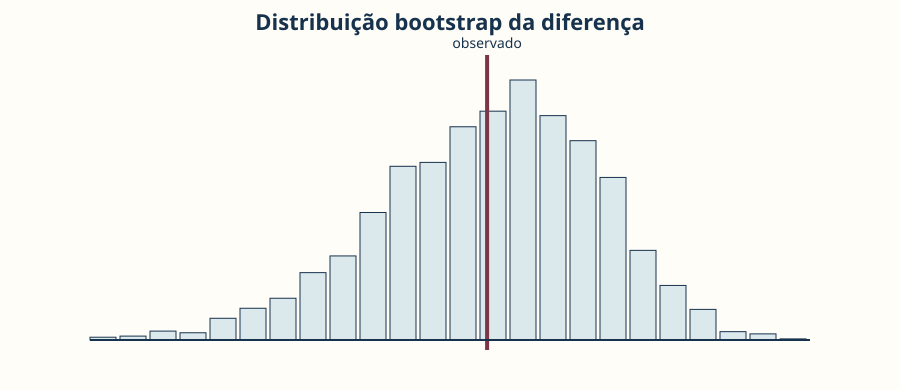

In [3]:
limite_inferior, limite_superior = np.quantile(diferencas_bootstrap, [0.025, 0.975])
tabela_intervalo = pd.DataFrame([{
    "estimativa": diferenca_observada,
    "limite inferior": limite_inferior,
    "limite superior": limite_superior,
    "unidade": "palavras por documento",
}])
display(tabela_intervalo.round(2))
histograma_referencia(diferencas_bootstrap, diferenca_observada, "Distribuição bootstrap da diferença")

O intervalo apresenta valores compatíveis com o procedimento de estimação. Um
teste responde a outra pergunta: quão incompatível é o resultado com um modelo
nulo especificado?

## 4. Hipótese nula e teste de permutação

A hipótese nula didática afirma que, sob permutação, os rótulos `Capital` e
`Interior` são intercambiáveis. Mantemos valores e tamanhos dos grupos,
embaralhamos os rótulos e recalculamos a diferença.

![Histograma de uma distribuição nula destaca as duas caudas e uma linha para o resultado observado, sem representar um limiar automático.](imagens/02_distribuicao_nula.svg)

Para $M$ permutações, uma estimativa bilateral com correção finita é:

$$
p=\frac{1+\sum_{m=1}^{M}\mathbf{1}(|T_m|\geq|T_{obs}|)}{M+1}.
$$

diferença observada    -203.1667
valor de p bilateral      0.1982
dtype: float64

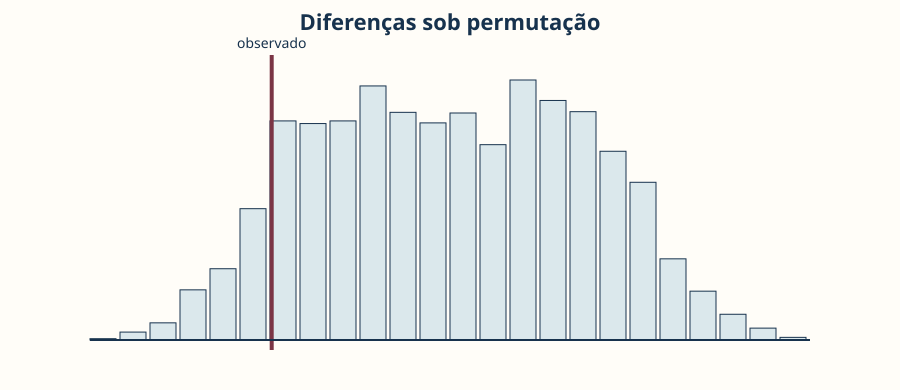

In [4]:
rng = np.random.default_rng(20260906)
combinados = np.concatenate([a, b])
M = 5000
permutadas = []
for _ in range(M):
    embaralhados = rng.permutation(combinados)
    permutadas.append(embaralhados[:len(a)].mean() - embaralhados[len(a):].mean())
diferencas_nulas = np.array(permutadas)
valor_p = (1 + np.sum(np.abs(diferencas_nulas) >= abs(diferenca_observada))) / (M + 1)
display(pd.Series({"diferença observada": diferenca_observada, "valor de p bilateral": valor_p}).round(4))
histograma_referencia(diferencas_nulas, diferenca_observada, "Diferenças sob permutação")

## 5. Como interpretar o valor de *p*

![Estimativa, intervalo, valor de p e contexto aparecem em quatro caixas distintas; nenhuma substitui desenho, transparência, teoria ou leitura dos casos.](imagens/02_mapa_interpretacao.svg)

O valor de *p* indica quão extremos seriam resultados como o observado sob a
hipótese nula e o procedimento especificado. Ele **não** informa:

- a probabilidade de a hipótese nula ser verdadeira;
- a importância do resultado;
- a probabilidade de replicação;
- a ausência de viés;
- a qualidade da operacionalização.

Conclusões não devem depender apenas de atravessar `0,05`. Relate estimativa,
intervalo, medida de efeito, desenho, decisões analíticas e contexto. A ASA
(Wasserstein e Lazar, 2016) fundamenta essas cautelas.

## Aplicação ao projeto Goodreads

As células seguintes aplicam as operações do notebook à base do projeto.
Especificação principal: **E2** (rótulo original sem os 1.274 livros
duvidosos): 4.638 livros de autoria feminina (F) e 4.542 de autoria masculina
(M). A ordem das diferenças é sempre **F − M**: valor negativo indica menos
reconhecimento para livros de autoras.

In [5]:
# Localiza a pasta do projeto Goodreads (localmente ou no Colab, se a pasta for enviada para /content)
import sys
from pathlib import Path

CANDIDATOS = [Path("../projeto_goodreads"), Path("projeto_goodreads"), Path("/content/projeto_goodreads")]
PROJETO = next((c.resolve() for c in CANDIDATOS if (c / "preparar_base.py").exists()), None)
if PROJETO is None:
    raise FileNotFoundError(
        "Pasta projeto_goodreads não encontrada. Coloque-a ao lado das pastas unidade_0X "
        "ou, no Colab, envie-a para /content."
    )
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))
print("Projeto localizado:", (PROJETO / "preparar_base.py").exists())
from preparar_base import carregar_base_analitica
import numpy as np
import pandas as pd
from IPython.display import display

base = carregar_base_analitica()
ESPEC = {"E1 original": "genero_E1_original",
         "E2 sem duvidosos (principal)": "genero_E2_sem_duvidosos",
         "E3 reclassificada": "genero_E3_reclassificado"}
GRUPO = "genero_E2_sem_duvidosos"
e2 = base[base[GRUPO].notna()].copy()
e2["muito_avaliado"] = e2["n_avaliacoes"] >= 10_000
F = e2[GRUPO].eq("feminino")
M = e2[GRUPO].eq("masculino")
print("Especificação principal E2:", int(F.sum()), "livros de autoria feminina e", int(M.sum()), "de autoria masculina")

Projeto localizado: True
Especificação principal E2: 4638 livros de autoria feminina e 4542 de autoria masculina


**Bootstrap e intervalo de confiança percentil** (B = 2.000; semente fixa). Reamostramos livros e, como alternativa, autores.

In [6]:
rng = np.random.default_rng(20261015)
a_med = e2.loc[F, "n_avaliacoes"].to_numpy()
b_med = e2.loc[M, "n_avaliacoes"].to_numpy()
a_log = e2.loc[F, "log10_avaliacoes"].to_numpy()
b_log = e2.loc[M, "log10_avaliacoes"].to_numpy()
B = 2000

def bootstrap_livros(x, y, estatistica, B):
    return np.array([estatistica(rng.choice(x, len(x), replace=True))
                     - estatistica(rng.choice(y, len(y), replace=True)) for _ in range(B)])

boot_mediana = bootstrap_livros(a_med, b_med, np.median, B)
boot_log = bootstrap_livros(a_log, b_log, np.mean, B)

# Bootstrap por autor: autores com vários livros não são observações independentes.
def bootstrap_autores(dados, coluna, estatistica, B):
    resultados = []
    grupos = {g: d.groupby("id_autor")[coluna].apply(np.array).to_list() for g, d in dados.groupby(GRUPO)}
    for _ in range(B):
        valores = {}
        for g, listas in grupos.items():
            escolhidos = rng.integers(0, len(listas), len(listas))
            valores[g] = estatistica(np.concatenate([listas[i] for i in escolhidos]))
        resultados.append(valores["feminino"] - valores["masculino"])
    return np.array(resultados)

boot_log_autor = bootstrap_autores(e2, "log10_avaliacoes", np.mean, B)

def intervalo(valores):
    return np.quantile(valores, [0.025, 0.975])

tabela_ic = pd.DataFrame([
    {"quantidade": "diferença de medianas de avaliações (F − M)", "estimativa": np.median(a_med) - np.median(b_med),
     **dict(zip(["limite inferior", "limite superior"], intervalo(boot_mediana))), "reamostragem": "livros"},
    {"quantidade": "diferença de médias de log10 avaliações (F − M)", "estimativa": a_log.mean() - b_log.mean(),
     **dict(zip(["limite inferior", "limite superior"], intervalo(boot_log))), "reamostragem": "livros"},
    {"quantidade": "diferença de médias de log10 avaliações (F − M)", "estimativa": a_log.mean() - b_log.mean(),
     **dict(zip(["limite inferior", "limite superior"], intervalo(boot_log_autor))), "reamostragem": "autores"},
])
tabela_ic.round(3)

,quantidade,estimativa,limite inferior,limite superior,reamostragem
0,diferença de medianas de avaliações (F − M),-2088.500,-2595.038,-1658.900,livros
1,diferença de médias de log10 avaliações (F − M),-0.176,-0.217,-0.137,livros
2,diferença de médias de log10 avaliações (F − M),-0.176,-0.225,-0.124,autores


In [7]:
# Mesmo procedimento para o engajamento (taxa de resenhas) e para o recorte 2010–2019
a_tx, b_tx = e2.loc[F, "taxa_resenhas"].to_numpy(), e2.loc[M, "taxa_resenhas"].to_numpy()
boot_taxa = bootstrap_livros(a_tx, b_tx, np.median, B)
recente = e2[e2["ano_publicacao"] >= 2010]
a_rec = recente.loc[recente[GRUPO].eq("feminino"), "log10_avaliacoes"].to_numpy()
b_rec = recente.loc[recente[GRUPO].eq("masculino"), "log10_avaliacoes"].to_numpy()
boot_rec = bootstrap_autores(recente, "log10_avaliacoes", np.mean, B)
pd.DataFrame([
    {"quantidade": "diferença de medianas da taxa de resenhas (F − M)", "estimativa": np.median(a_tx) - np.median(b_tx),
     **dict(zip(["limite inferior", "limite superior"], intervalo(boot_taxa))), "reamostragem": "livros"},
    {"quantidade": "diferença de médias de log10 avaliações, 2010–2019 (F − M)", "estimativa": a_rec.mean() - b_rec.mean(),
     **dict(zip(["limite inferior", "limite superior"], intervalo(boot_rec))), "reamostragem": "autores"},
]).round(4)

,quantidade,estimativa,limite inferior,limite superior,reamostragem
0,diferença de medianas da taxa de resenhas (F − M),0.0377,0.0337,0.0415,livros
1,"diferença de médias de log10 avaliações, 2010–...",0.1920,0.1178,0.2627,autores


**Teste de permutação** (M = 5.000) para a diferença de médias de log10 das avaliações.

In [8]:
rng = np.random.default_rng(20261015)
combinados = np.concatenate([a_log, b_log])
n_a = len(a_log)
observada = a_log.mean() - b_log.mean()
M_perm = 5000
nulas = np.empty(M_perm)
for m in range(M_perm):
    embaralhado = rng.permutation(combinados)
    nulas[m] = embaralhado[:n_a].mean() - embaralhado[n_a:].mean()
valor_p = (1 + np.sum(np.abs(nulas) >= abs(observada))) / (M_perm + 1)
pd.Series({
    "diferença observada (log10)": observada,
    "maior |diferença| sob permutação": np.abs(nulas).max(),
    "valor de p bilateral (com correção finita)": valor_p,
    "menor valor de p possível com M = 5000": 1 / (M_perm + 1),
}).round(5)

diferença observada (log10)                  -0.17641
maior |diferença| sob permutação              0.06867
valor de p bilateral (com correção finita)    0.00020
menor valor de p possível com M = 5000        0.00020
dtype: float64

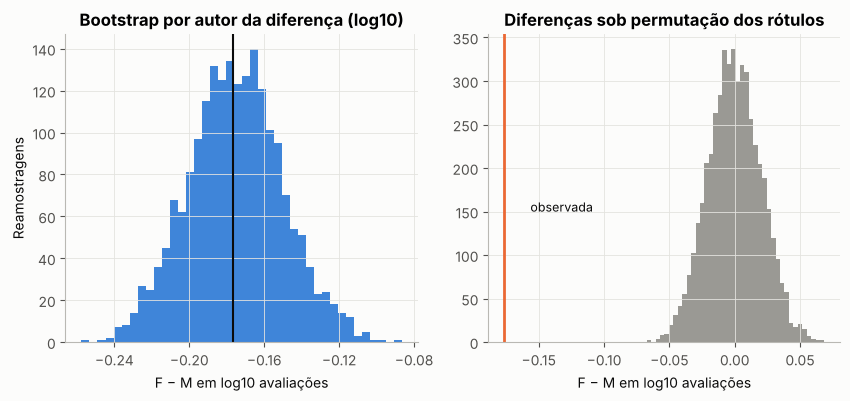

In [9]:
from graficos_projeto import CORES, estilo, salvar
import matplotlib.pyplot as plt
estilo()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.hist(boot_log_autor, bins=40, color="#2a78d6", alpha=0.9)
ax1.axvline(observada, color="#0b0b0b", linewidth=1.5)
ax1.set_title("Bootstrap por autor da diferença (log10)")
from matplotlib.ticker import MaxNLocator
ax1.xaxis.set_major_locator(MaxNLocator(5))
ax1.set_xlabel("F − M em log10 avaliações")
ax1.set_ylabel("Reamostragens")
ax2.hist(nulas, bins=40, color="#9a9994")
ax2.axvline(observada, color="#eb6834", linewidth=2)
ax2.set_title("Diferenças sob permutação dos rótulos")
ax2.set_xlabel("F − M em log10 avaliações")
ax2.annotate("observada", xy=(observada, 0), xytext=(observada + 0.02, 150), color="#0b0b0b", fontsize=9)
salvar(fig, "fig6_bootstrap_permutacao.png")
plt.show()

*Descrição alternativa da figura:* à esquerda, histograma das 2.000
diferenças bootstrap (reamostragem por autor), concentradas entre cerca de −0,23 e
−0,12, com linha vertical na diferença observada (−0,176). À direita, histograma
das 5.000 diferenças sob permutação, centradas em zero e todas entre −0,07 e
0,07; a linha laranja da diferença observada fica bem fora dessa nuvem.

## 6. Significância e relevância substantiva

Uma diferença muito pequena pode produzir valor de *p* baixo em grande amostra;
uma diferença importante pode permanecer imprecisa em amostra pequena. A
relevância depende da pergunta, da escala, das consequências e da literatura.

> **Nota sobre atividades em dupla, trio ou revisão por pares.** Esta resolução
> foi produzida por uma única pessoa. Onde o roteiro pede colegas, apresento uma
> **revisão crítica simulada**, guiada pelas perguntas do roteiro. Ela não
> substitui o trabalho e o parecer de colegas reais.

### U05-A03 — Atividade integrada — ficha inferencial

**Modalidade:** dupla. **Tempo:** 30
minutos.

1. declare população-alvo e procedimento de seleção;
2. informe estimativa, intervalo e tamanho de efeito;
3. formule a hipótese nula do teste;
4. interprete o valor de *p* sem decisão binária;
5. indique duas fontes de incerteza não representadas;
6. escreva uma conclusão substantiva limitada.

**Minha ficha:**

1. **População-alvo e seleção.** Não há população-alvo definida com
   segurança. O alvo hipotético seria “livros catalogados no Goodreads com
   perfil semelhante ao do recorte”, mas o recorte é uma coleção de
   conveniência com critério desconhecido. Por isso, os intervalos abaixo
   medem apenas a variabilidade de reamostrar este recorte, tratado *como se*
   viesse de um procedimento repetível, como faz o próprio notebook com os
   dados fictícios.
2. **Estimativa, intervalo e efeito.** Quantidade principal: diferença de
   médias de log10 das avaliações, F − M = −0,176 (razão de médias geométricas
   de 0,67; d = −0,18). Intervalo bootstrap percentil de 95%, reamostrando
   livros: [−0,217; −0,137]. Reamostrando **autores** (porque livros do mesmo
   autor não são independentes): [−0,225; −0,124], um pouco mais largo, como
   esperado. Diferença de medianas: −2.089 avaliações, intervalo
   [−2.595; −1.659]. Para livros de 2010 a 2019, a diferença em log10 é
   **+0,192**, com intervalo por autores de [0,118; 0,263]. Taxa de resenhas:
   +0,038 [0,034; 0,042] no agregado, diferença que desaparece dentro de cada
   ano (Notebook 01).
3. **Hipótese nula.** Os rótulos F e M são intercambiáveis em relação ao log10
   das avaliações: se os rótulos fossem distribuídos ao acaso entre os mesmos
   9.180 livros, a diferença observada seria comum.
4. **Valor de *p*.** Em 5.000 permutações, nenhuma diferença chegou perto da
   observada (a maior, em valor absoluto, foi 0,069, contra 0,176 observada).
   O valor de *p* com correção finita é 0,0002, que é o menor valor possível com
   5.000 permutações. Leitura: a diferença agregada seria muito incomum se os
   rótulos fossem intercambiáveis. Isso **não** diz que a diferença é
   importante, que tem causa no gênero da autoria nem que se aplica ao
   Goodreads inteiro. Com 9.180 livros, até diferenças pequenas produzem *p*
   muito baixo.
5. **Fontes de incerteza não representadas:** (a) o mecanismo de seleção do
   recorte, desconhecido; (b) o erro restante no rótulo de gênero, mesmo após a
   exclusão dos duvidosos (por exemplo, nomes sem prenome classificável);
   (c) a composição temporal, que inverte o sinal quando se compara dentro de
   cada ano; (d) a data da coleta, que define até quando as avaliações foram
   contadas.
6. **Conclusão substantiva limitada.** Neste recorte, livros de autoria
   registrada como feminina recebem, em conjunto, cerca de um terço menos
   avaliações (em média geométrica) que livros de autoria masculina, e essa
   diferença é estável sob reamostragem de livros e de autores. Entretanto, a
   diferença depende da composição temporal: entre livros publicados de 2010 a
   2019, os de autoras recebem mais avaliações. O intervalo não corrige nenhum
   desses problemas de desenho.

**Situação em que eu não aplicaria inferência amostral:** se eu tivesse todos
os livros catalogados no Goodreads em uma data (o universo completo da
pergunta), a diferença já seria o resultado; o interesse passaria a ser sua
magnitude, sua estabilidade no tempo e sua explicação. Também não aplicaria se
a seleção fosse conhecida e claramente dependente do resultado (por exemplo,
apenas livros de listas de mais avaliados), porque a reamostragem herdaria o
viés.

O eixo quantitativo está completo. No Notebook 03, a comparação muda de objeto:
representaremos documentos como termos e pesos antes de calcular semelhanças.